<a href="https://colab.research.google.com/github/TapaswiniHaldar/tabular-churn-classifier/blob/main/telco_churn_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url, na_values=[" ", ""])
df = df.drop(columns=["customerID"])


=== COPY THIS TABLE ===
| ML Model Name            |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
|:-------------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
| Logistic Regression      |     0.8028 | 0.8403 |      0.661  |   0.5242 | 0.5847 | 0.463  |
| Decision Tree            |     0.7765 | 0.7945 |      0.5848 |   0.5376 | 0.5602 | 0.4114 |
| kNN                      |     0.7609 | 0.7921 |      0.5529 |   0.5054 | 0.5281 | 0.369  |
| Naive Bayes              |     0.6861 | 0.8092 |      0.4501 |   0.836  | 0.5851 | 0.4132 |
| Random Forest (Ensemble) |     0.8    | 0.8337 |      0.6619 |   0.5    | 0.5697 | 0.4501 |


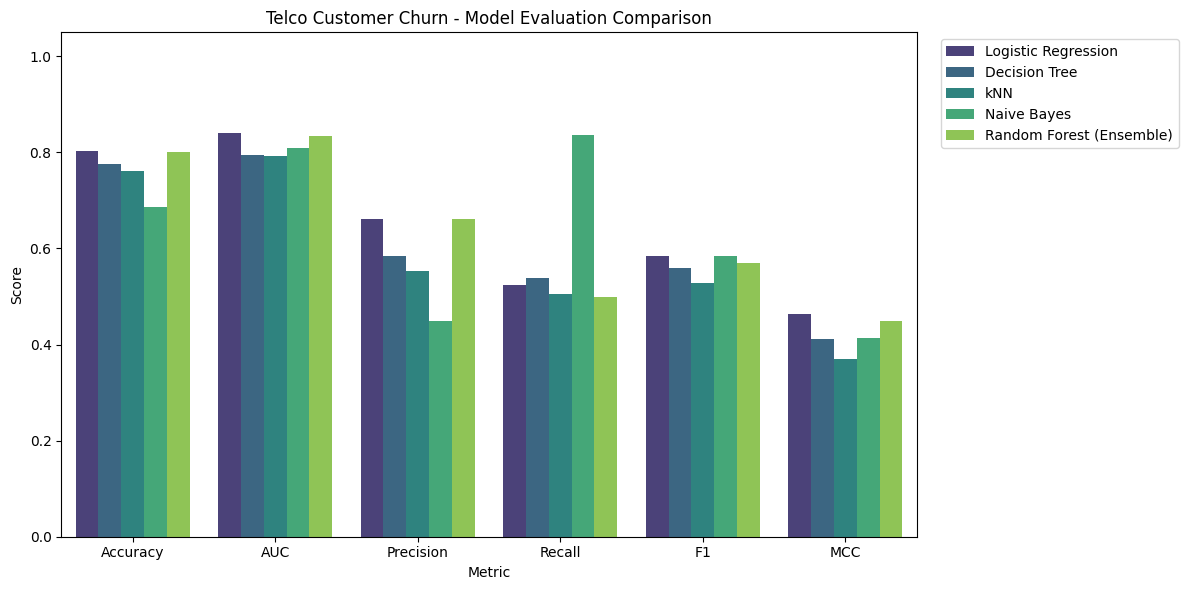

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import os
import zipfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

SEED = 42
np.random.seed(SEED)

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url, na_values=[" ", ""])
df = df.drop(columns=["customerID"]).drop_duplicates().reset_index(drop=True)

TARGET_COL = "Churn"
X = df.drop(columns=[TARGET_COL])
y_raw = df[TARGET_COL]

le = LabelEncoder()
y = le.fit_transform(y_raw)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

test_export = X_test.copy()
test_export[TARGET_COL] = y_raw.iloc[X_test.index].values
test_export.to_csv("test_data.csv", index=False)

num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), cat_cols)
])

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=SEED),
    "kNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Random Forest (Ensemble)": RandomForestClassifier(n_estimators=150, max_depth=10, random_state=SEED)
}

os.makedirs("model", exist_ok=True)
results = []

for name, clf in models.items():
    clf.fit(X_train_proc, y_train)
    safe_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    joblib.dump(clf, f"model/{safe_name}.pkl")

    y_pred = clf.predict(X_test_proc)
    y_prob = clf.predict_proba(X_test_proc)[:, 1]

    results.append({
        "ML Model Name": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "AUC": round(roc_auc_score(y_test, y_prob), 4),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "F1": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "MCC": round(matthews_corrcoef(y_test, y_pred), 4)
    })

results_df = pd.DataFrame(results)
print("\n=== COPY THIS TABLE ===")
print(results_df.to_markdown(index=False))

melted_df = results_df.melt(id_vars="ML Model Name", var_name="Metric", value_name="Score")
plt.figure(figsize=(12, 6))
sns.barplot(data=melted_df, x="Metric", y="Score", hue="ML Model Name", palette="viridis")
plt.title("Telco Customer Churn - Model Evaluation Comparison")
plt.ylim(0, 1.05)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("metrics_comparison.png", dpi=300)
plt.show()

with zipfile.ZipFile("assignment_outputs.zip", "w") as zf:
    zf.write("test_data.csv")
    zf.write("metrics_comparison.png")
    for fname in os.listdir("model"):
        zf.write(os.path.join("model", fname))

files.download("assignment_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>